# Regresión: SVR (RBF)

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "svr"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,SVR (RBF)
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |

En las tres, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** El modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Se exploraron 20 combinaciones de `C` (log-uniforme entre 0.1 y 100: cuánto se penalizan los errores fuera del tubo), `epsilon` (log-uniforme entre 0.01 y 5: ancho del tubo en el que los errores no cuentan) y `gamma` (`"scale"` en ~la mitad de las combinaciones o log-uniforme entre 1e-3 y 1). `epsilon` está en la escala en que se entrena el target: con sqrt (0–7.9) o log1p (0–4.2) el mismo valor es mucho más ancho que en puntos BDI, y con `epsilon` muy grande casi no quedan vectores de soporte y la predicción es casi constante.

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
C,log-uniforme entre 0.1 y 100
epsilon,log-uniforme entre 0.01 y 5
gamma,scale o log-uniforme entre 0.001 y 1


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 7.0649 ± 0.5386  R² = 0.1626  (10 s)
✓ sqrt + smearing    RMSE = 6.8862 ± 0.4936  R² = 0.2043  (12 s)
✓ log1p + smearing   RMSE = 6.9367 ± 0.4867  R² = 0.1924  (12 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,7.065 ± 0.539,4.727 ± 0.204,0.163 ± 0.032,10.0
sqrt + smearing,6.886 ± 0.494,4.884 ± 0.188,0.204 ± 0.018,12.0
log1p + smearing,6.937 ± 0.487,4.922 ± 0.201,0.192 ± 0.020,12.0


Aquí la transformación sí importa. sqrt obtiene el menor RMSE (6.886 ± 0.494) y el mayor R² (0.204 ± 0.018), el mejor resultado entre los modelos que no son de árboles. log1p queda cerca (6.937, R² = 0.192) y el nativo es claramente el peor (7.065, R² = 0.163).

En MAE el orden se invierte: el nativo tiene el menor (4.727). La pérdida ε-insensible del SVR penaliza los errores de forma lineal, como el MAE. Por eso, en la escala nativa el modelo se acerca a la mediana condicional del BDI, que en una distribución asimétrica está por debajo de la media: gana en MAE y pierde en RMSE. Al entrenar en sqrt y retransformar con smearing, la predicción vuelve a apuntar a la media.

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,C,epsilon,gamma
Variante,,,
Nativo,65.8400,2.6010,0.06219
sqrt + smearing,0.9542,0.3464,0.03652
log1p + smearing,0.1173,0.2608,0.01583


El nativo necesita una penalización alta (`C` = 65.8) y un tubo ancho (`epsilon` = 2.6 puntos BDI). sqrt y log1p eligen valores de `C` mucho menores (0.95 y 0.12) y tubos de 0.35 y 0.26 en su escala, coherentes con un target de menor rango. `gamma` va de 0.016 a 0.062: son kernels suaves, sin efectos muy locales.

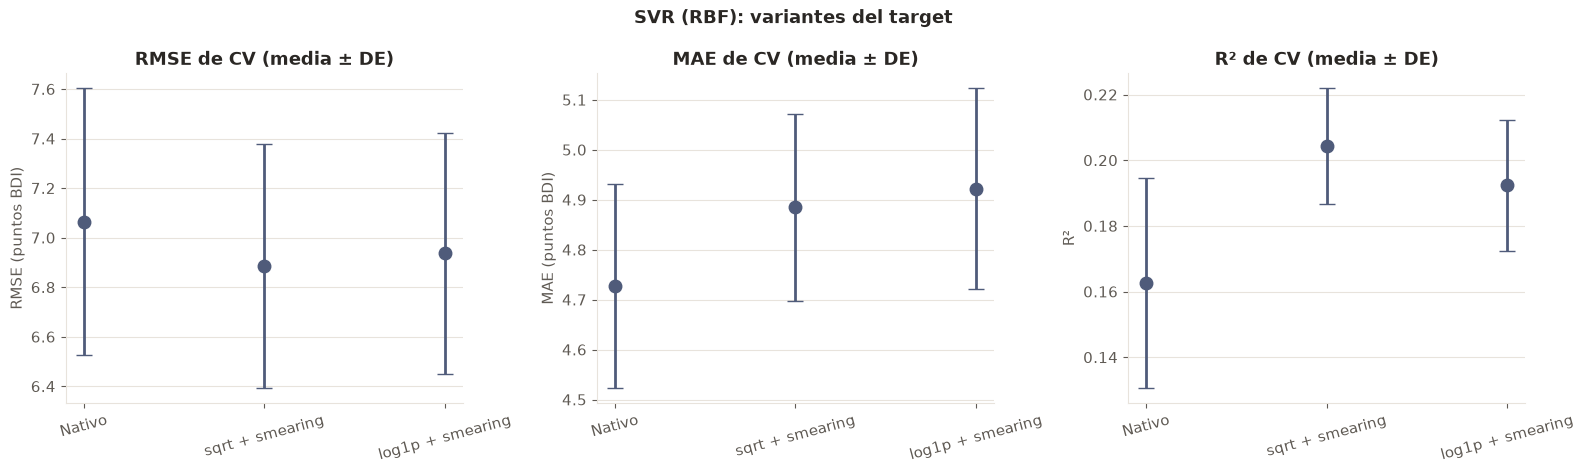

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica muestra la caída del nativo en RMSE y R² y su ventaja en MAE. Entre sqrt y log1p las diferencias son pequeñas.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.489,-1.813,7.139,4.628,0.151
Con smearing,7.253,-0.049,6.904,4.884,0.205


Sin smearing, la media predicha con sqrt es 5.49, 1.81 puntos por debajo de la real. Con la corrección queda en 7.25, el RMSE baja de 7.139 a 6.904 y el R² sube de 0.151 a 0.205. Igual que en los modelos lineales, el MAE empeora (de 4.628 a 4.884) porque la corrección desplaza la predicción de la mediana a la media.

### Selección del Mejor Modelo SVR (RBF)

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,SVR (RBF)
Variante ganadora,Nativo
RMSE de CV,7.0649 ± 0.5386
MAE de CV,4.7274 ± 0.2045
R² de CV,0.1626 ± 0.0320
Hiperparámetros,"C=65.84, epsilon=2.601, gamma=0.06219"
Criterio,"El menor RMSE medio de CV es el de 'sqrt + smearing' (6.8862 ± 0.4936), pero 'Nativo' es más simple y su RMSE (7.0649) está a solo 0.1786 puntos, menos que la desviación estándar de CV de la ganadora (0.4936). Por la regla de empate se elige 'Nativo'."


sqrt tiene el menor RMSE medio (6.8862) y el nativo está a 0.179 puntos, por debajo de la desviación entre folds (0.494). Por la regla de empate se elige el nativo.

Es la aplicación más discutible de la regla en la fase 1. La diferencia de R² (0.204 frente a 0.163) es más del doble de su desviación entre folds (0.018 a 0.032), así que la ventaja de sqrt probablemente es real. La regla usa la desviación del RMSE, que es grande porque los folds difieren en la dispersión del BDI. Por eso el SVR pasa a la fase 2 con un RMSE peor que el que podría tener.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/svr: resultados_cv.csv, ganador.json y svr_nativo.joblib
